# Регрессионный анализ

В `train.csv` есть ответы для обучения, а `test.csv` содержит только признаки для финальных прогнозов.

**Задача:**  
Необходимо предсказать суточное удельное теплопотребление здания heat_kwh_m2, кВт·ч/м² за сутки, по погоде, характеристикам здания и режиму эксплуатации.

## Данные участника

ФИО: Веремчук Александра Олеговна  
Email: veremchuk.alexandra@gmail.com  
ВУЗ: ИТМО  


## Словарь ThermoCampus 2026 v1

Строка — здание в один из 16 наблюдавшихся дней.

| Поле | Значение |
|---|---|
| row_id | Случайный непрозрачный ID строки, ключ прогнозов |
| building_id | ID здания для группового разбиения |
| building_type | residential — жилое, office — офисное, education — учебное |
| wall_type | brick — кирпич, panel — панель, monolith — монолит |
| control_type | manual — ручное, weather — погодное, smart — адаптивное управление |
| floor_area_m2 | Общая площадь, м² |
| age_years | Возраст здания, лет |
| floors | Этажность |
| insulation_mm | Толщина утепления, мм; возможны пропуски |
| glazing_ratio | Доля остекления наружной поверхности, 0–1 |
| boiler_efficiency | КПД отопительной установки, 0–1 |
| ventilation_ach | Воздухообмен, 1/час; возможны пропуски |
| day_of_season | Номер дня условного отопительного сезона, 1–150 |
| outdoor_temp_c | Средняя наружная температура, °C |
| wind_m_s | Средняя скорость ветра, м/с |
| solar_kwh_m2 | Суточная солнечная радиация, кВт·ч/м²; возможны пропуски |
| humidity_pct | Относительная влажность, %; возможны пропуски |
| is_weekend | 1 — выходной день, 0 — будний |
| occupancy_ratio | Доля присутствующих от типовой вместимости, 0–1 |
| setpoint_c | Заданная температура внутри, °C |
| heat_kwh_m2 | Цель: суточное удельное теплопотребление, кВт·ч/м²; только в train |



## Загрузка данных

In [19]:
import json, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
print('Train / test:', train.shape, test.shape)
print('Train buildings:', train.building_id.nunique())
print('Target:', train.heat_kwh_m2.describe().round(3).to_dict())
print('Missing:', train.isna().sum()[lambda s: s > 0].to_dict())

Train / test: (8960, 21) (3840, 20)
Train buildings: 560
Target: {'count': 8960.0, 'mean': 0.698, 'std': 0.337, 'min': 0.005, '25%': 0.437, '50%': 0.672, '75%': 0.926, 'max': 2.407}
Missing: {'control_type': 175, 'insulation_mm': 529, 'ventilation_ach': 380, 'solar_kwh_m2': 354, 'humidity_pct': 273}


In [21]:
train.head()

,row_id,building_id,building_type,wall_type,control_type,floor_area_m2,age_years,floors,insulation_mm,glazing_ratio,...,ventilation_ach,day_of_season,outdoor_temp_c,wind_m_s,solar_kwh_m2,humidity_pct,is_weekend,occupancy_ratio,setpoint_c,heat_kwh_m2
0,13ee61c2a2b7b823b3,B0060,office,monolith,NaN,9355.0,3,8,137.72,0.2807,...,0.7426,18,-1.68,1.79,1.331,53.00,0,0.5060,21.23,0.516555
1,cdfe47470023c2ac9a,B0254,education,panel,smart,11867.2,41,14,154.79,0.4350,...,0.2550,131,-15.21,9.08,4.914,40.90,0,0.8031,18.24,0.702161
2,655e9e237d60b43766,B0441,education,panel,manual,3682.8,14,2,92.26,0.1646,...,1.0028,54,6.82,4.03,3.613,77.07,0,0.7998,21.41,0.539114
3,f30492936daadc727d,B0257,education,brick,weather,9735.9,28,9,NaN,0.2957,...,0.4955,39,6.64,2.42,0.804,53.40,0,0.6893,21.71,0.354260
4,cd22c22a58ff724ab2,B0501,education,panel,NaN,4282.1,50,9,47.20,0.1466,...,0.2401,13,-0.03,4.86,0.151,76.66,0,0.7433,19.51,0.505028


## EDA

In [22]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8960 entries, 0 to 8959
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   row_id             8960 non-null   object 
 1   building_id        8960 non-null   object 
 2   building_type      8960 non-null   object 
 3   wall_type          8960 non-null   object 
 4   control_type       8785 non-null   object 
 5   floor_area_m2      8960 non-null   float64
 6   age_years          8960 non-null   int64  
 7   floors             8960 non-null   int64  
 8   insulation_mm      8431 non-null   float64
 9   glazing_ratio      8960 non-null   float64
 10  boiler_efficiency  8960 non-null   float64
 11  ventilation_ach    8580 non-null   float64
 12  day_of_season      8960 non-null   int64  
 13  outdoor_temp_c     8960 non-null   float64
 14  wind_m_s           8960 non-null   float64
 15  solar_kwh_m2       8606 non-null   float64
 16  humidity_pct       8687 

In [23]:
train.describe()

,floor_area_m2,age_years,floors,insulation_mm,glazing_ratio,boiler_efficiency,ventilation_ach,day_of_season,outdoor_temp_c,wind_m_s,solar_kwh_m2,humidity_pct,is_weekend,occupancy_ratio,setpoint_c,heat_kwh_m2
count,8960.000000,8960.000000,8960.000000,8431.000000,8960.000000,8960.000000,8580.000000,8960.000000,8960.000000,8960.000000,8606.000000,8687.000000,8960.000000,8960.000000,8960.000000,8960.000000
mean,7504.063214,40.542857,10.085714,106.487302,0.329287,0.819060,0.613389,76.201562,-3.042114,3.366333,1.279513,69.067370,0.289621,0.618342,20.814124,0.698412
std,3762.021009,22.329198,4.805006,43.477543,0.120696,0.080839,0.269033,43.637849,9.859886,2.176927,0.895162,16.747484,0.453612,0.224883,1.317703,0.336618
min,809.900000,3.000000,2.000000,30.140000,0.120700,0.681400,0.150200,1.000000,-26.000000,0.030000,0.011000,40.010000,0.000000,0.030000,15.270000,0.005000
25%,4146.575000,21.000000,6.000000,69.840000,0.228650,0.750350,0.386000,38.000000,-11.000000,1.770000,0.620000,54.650000,0.000000,0.537650,19.980000,0.437459
50%,7632.400000,40.500000,10.000000,105.710000,0.330350,0.818900,0.610100,76.000000,-3.010000,2.920000,1.077000,69.430000,0.000000,0.678400,20.840000,0.671768
75%,10720.850000,59.000000,14.000000,143.750000,0.429400,0.886225,0.838600,114.000000,4.900000,4.440000,1.723000,83.470000,1.000000,0.772800,21.710000,0.926441
max,13985.300000,79.000000,18.000000,179.970000,0.549900,0.958200,1.099800,150.000000,19.000000,17.750000,5.500000,97.990000,1.000000,1.000000,25.700000,2.407481


In [24]:
train.describe(include="object")

,row_id,building_id,building_type,wall_type,control_type
count,8960,8960,8960,8960,8785
unique,8960,560,3,3,3
top,13ee61c2a2b7b823b3,B0060,office,brick,smart
freq,1,16,3136,3344,2970


In [25]:
# Объединяем признаки train и test для полной проверки закономерностей
full_df = pd.concat(
    [train.drop(columns=['heat_kwh_m2']), test], ignore_index=True
)

b_cols = ['control_type', 'insulation_mm', 'ventilation_ach']
w_cols = ['outdoor_temp_c', 'wind_m_s', 'solar_kwh_m2', 'humidity_pct']
# параметры здания
b_nunique = full_df.groupby('building_id')[b_cols].nunique(dropna=True)
print('Максимум уникальных значений у одного здания (должно быть 1):')
print(b_nunique.max())
# погода
w_nunique = full_df.groupby('day_of_season')[w_cols].nunique(dropna=True)
print('Максимум уникальных значений погоды в один день (1 = погода единая):')
print(w_nunique.max())

Максимум уникальных значений у одного здания (должно быть 1):
control_type       1
insulation_mm      1
ventilation_ach    1
dtype: int64
Максимум уникальных значений погоды в один день (1 = погода единая):
outdoor_temp_c    103
wind_m_s           99
solar_kwh_m2      103
humidity_pct      104
dtype: int64


**Выводы**  
Надо заполнить пропуски в столбцах:  
* `control_type` - можно воостановить, тк не меняются ото дня ко дню для одного и того же building_id;
* `insulation_mm` - можно воостановить, тк не меняются ото дня ко дню для одного и того же building_id;  
* `ventilation_ach` - можно воостановить, тк не меняются ото дня ко дню для одного и того же building_id;  
* `solar_kwh_m2` - для заполнения используем ср. значение;  
* `humidity_pct` - для заполнения используем ср. значение.   

И закодировать категориальные признаки при помощи `OneHotEncoding`:   
* `building_type`,  
* `wall_type`,   
* `control_type`.  

### Заполнение пропусков   

In [26]:
# Восстанавливаем параметры зданий по building_id
b_cols = ['control_type', 'insulation_mm', 'ventilation_ach']
for df in [train, test]:
  for col in b_cols:
    df[col] = df[col].fillna(df.groupby('building_id')[col].transform('first'))

# Заполняем погодные пропуски медианой по train + создаём флаги пропусков
w_na_cols = ['solar_kwh_m2', 'humidity_pct']
for col in w_na_cols:
  med = train[col].median()
  for df in [train, test]:
    df[f'{col}_is_na'] = df[col].isna().astype(int)
    df[col] = df[col].fillna(med)

print('Пропусков в train:', train.isna().sum().sum())
print('Пропусков в test: ', test.isna().sum().sum())


Пропусков в train: 0
Пропусков в test:  0


### Кодируем признаки
Кодируем категориальные признаки при помощи `OneHotEncoding`.   

In [28]:
cat_cols = ['building_type', 'wall_type', 'control_type']

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

train_encoded = ohe.fit_transform(train[cat_cols])
test_encoded = ohe.transform(test[cat_cols])
encoded_cols = ohe.get_feature_names_out(cat_cols)

train_ohe_df = pd.DataFrame(train_encoded, columns=encoded_cols, index=train.index)
test_ohe_df = pd.DataFrame(test_encoded, columns=encoded_cols, index=test.index)

train = pd.concat([train.drop(columns=cat_cols), train_ohe_df], axis=1)
test = pd.concat([test.drop(columns=cat_cols), test_ohe_df], axis=1)

print('Новые закодированные столбцы:', list(encoded_cols))
print('Итоговая размерность train и test:', train.shape, test.shape)

Новые закодированные столбцы: ['building_type_education', 'building_type_office', 'building_type_residential', 'wall_type_brick', 'wall_type_monolith', 'wall_type_panel', 'control_type_manual', 'control_type_smart', 'control_type_weather']
Итоговая размерность train и test: (8960, 29) (3840, 28)


### Матрица Корреляции

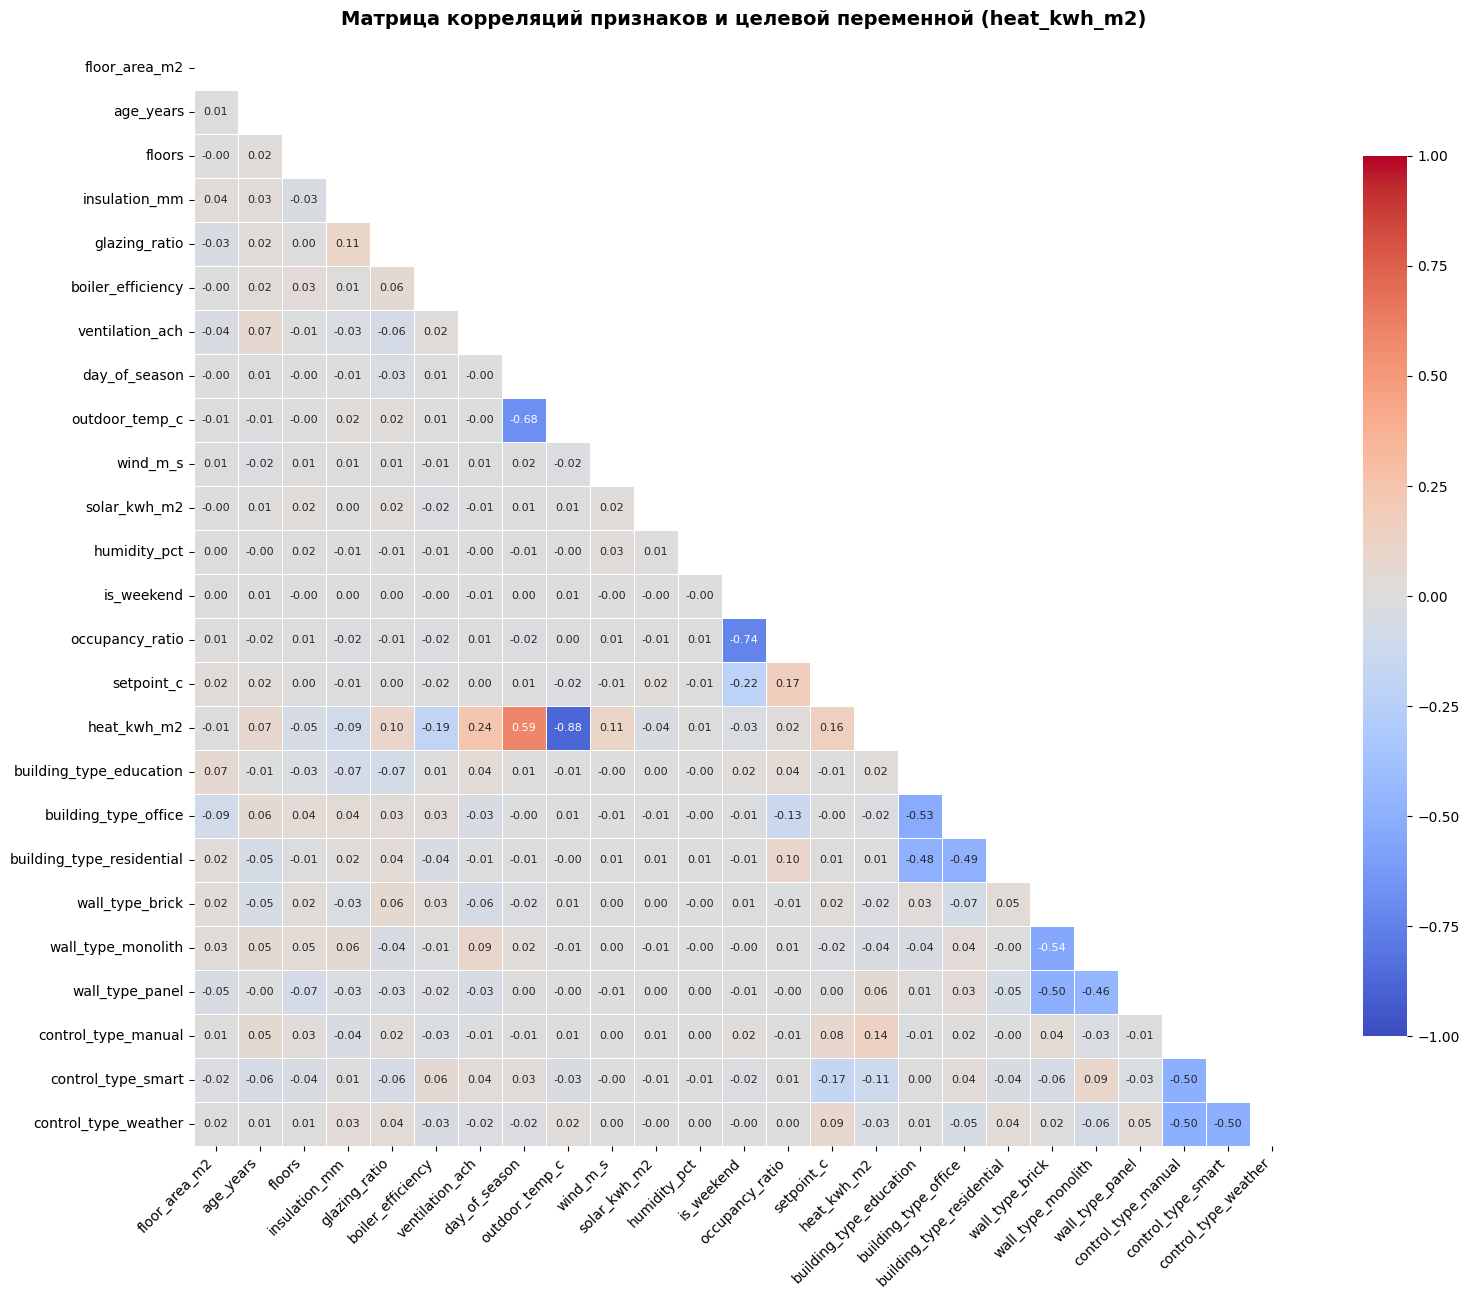

Сила связи признака с целевой переменной heat_kwh_m2:
outdoor_temp_c              -0.876
day_of_season                0.591
ventilation_ach              0.241
boiler_efficiency           -0.195
setpoint_c                   0.156
control_type_manual          0.142
control_type_smart          -0.112
wind_m_s                     0.107
glazing_ratio                0.097
insulation_mm               -0.091
age_years                    0.075
wall_type_panel              0.059
floors                      -0.049
wall_type_monolith          -0.039
solar_kwh_m2                -0.036
control_type_weather        -0.029
is_weekend                  -0.027
building_type_office        -0.022
occupancy_ratio              0.019
wall_type_brick             -0.018
building_type_education      0.016
floor_area_m2               -0.010
humidity_pct                 0.008
building_type_residential    0.006
Name: heat_kwh_m2, dtype: float64


In [30]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

main_cols = [
    c
    for c in train.columns
    if c not in ['row_id', 'building_id'] and not c.endswith('_is_na')
]

# Добавлен параметр numeric_only=True для игнорирования текстовых колонок
corr_matrix = train[main_cols].corr(numeric_only=True)

plt.figure(figsize=(16, 13))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    annot_kws={'size': 8},
)

plt.title(
    'Матрица корреляций признаков и целевой переменной (heat_kwh_m2)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print('Сила связи признака с целевой переменной heat_kwh_m2:')
target_corr = corr_matrix['heat_kwh_m2'].drop('heat_kwh_m2')
print(
    target_corr.reindex(
        target_corr.abs().sort_values(ascending=False).index
    ).round(3)
)

**Выводы**  
1. Больше всего на потребление тепла влияют:   
* `outdoor_temp_c` (-0.876): чем холоднее на улице, тем выше расход тепла.
* `day_of_season` (+0.591): второй по силе фактор. При этом между `day_of_season`и `outdoor_temp_c` корреляция -0.68 (к концу условного сезона становится холоднее). Это значит, что износ/остывание конструкций или календарный сдвиг вносят свой вклад поверх самой температуры.
* `ventilation_ach` (+0.241): нагрев приточного воздуха с улицы забирает огромную долю энергии.

Мультиколлинеарности не обнаружено. Ничего удалять не нужно.   
Можно подумать о Feature engineering.

## Feature Engineering

Для повышения точности моделей на основе законов строительной теплофизики и режимов эксплуатации зданий сконструировано **26 новых признаков**, сгруппированных в 7 логических блоков:

1. **Температурный напор и порог отопления (`delta_t`, `delta_t_pos`, `delta_t_soft`, `is_heating`)**
   * Разница температур внутри и снаружи ($\Delta T = T_{\text{внутр}} - T_{\text{наруж}}$) определяет интенсивность теплоотдачи по закону Фурье.
   * Бинарный индикатор `is_heating` и обнулённый напор `delta_t_pos` фиксируют отключение отопления в тёплую погоду, а функция *Softplus* (`delta_t_soft = log(1 + exp(ΔT))`) обеспечивает гладкий переход вблизи точки включения котла.

2. **Геометрия ограждающих конструкций (`roof_factor`, `wall_factor`)**
   * Удельная площадь кровли на $1\text{ м}^2$ общей площади обратно пропорциональна числу этажей (`1 / floors`), а удельный периметр наружных стен пропорционален $\sqrt{\text{floors} / \text{floor\_area\_m2}}$.

3. **Теплопередача через оболочку, вентиляцию и ветер (`u_wall`, `q_wall`, `q_roof`, `q_window`, `q_vent`, `q_wind`)**
   * Коэффициент теплопередачи утеплителя (`u_wall = 1 / (insulation_mm + 10)`) позволяет раздельно рассчитать удельные теплопотери через глухую часть стен (`q_wall`), кровлю (`q_roof`) и остекление (`q_window`).
   * Признаки `q_vent` и `q_wind` учитывают затраты тепла на подогрев приточного воздуха и инфильтрацию от ветра пропорционально температурному напору.

4. **Бесплатные теплопоступления и режим работы (`q_solar`, `occ_workday`)**
   * Солнечная радиация через окна (`solar_kwh_m2 * glazing_ratio`) снижает потребность в отоплении, а внутренние тепловыделения от людей и техники максимальны в рабочие будни (`occupancy_ratio * (1 - is_weekend)`).

5. **Поправка энергетических потоков на КПД котельной (`inv_eff` и серия признаков `*_eff`)**
   * Целевая переменная `heat_kwh_m2` учитывает потери отопительной установки. Умножение всех ключевых тепловых потоков на обратный КПД (`1 / boiler_efficiency`) переводит чистую тепловую нагрузку в реальный расход энергии.

6. **Гармоники отопительного сезона (`season_sin`, `season_cos`)**
   * Тригонометрическое кодирование дня сезона (`day_of_season` с периодом 150 дней) отражает плавную сезонную динамику без разрывов на границах интервала.

7. **Поведенческие эффекты автоматики и ручного управления (`manual_warm`, `smart_saving`)**
   * При ручном управлении (`manual_warm`) в тёплые дни возникает избыточный расход тепла («перетоп») из-за инерции регулирования, а умная автоматика (`smart_saving`) снижает подачу тепла в периоды низкой заполняемости помещений.

In [31]:
def create_physics_features(df: pd.DataFrame) -> pd.DataFrame:
  """Генерирует физические и эксплуатационные признаки теплопотребления здания."""
  d = df.copy()

  # 1. Температурный напор и плавный переход порога отопления
  d['delta_t'] = d['setpoint_c'] - d['outdoor_temp_c']
  d['delta_t_pos'] = np.maximum(0.0, d['delta_t'])
  d['delta_t_soft'] = np.log1p(np.exp(d['delta_t']))
  d['is_heating'] = (d['delta_t'] > 0).astype(float)

  # 2. Геометрия ограждающих конструкций (удельная площадь крыши и стен на 1 м² пола)
  d['roof_factor'] = 1.0 / d['floors']
  d['wall_factor'] = np.sqrt(d['floors'] / d['floor_area_m2'])

  # 3. Сопротивление теплопередаче и компоненты теплопотерь
  d['u_wall'] = 1.0 / (d['insulation_mm'] + 10.0)
  d['q_wall'] = (
      d['delta_t_pos'] * d['u_wall'] * d['wall_factor'] * (1.0 - d['glazing_ratio'])
  )
  d['q_roof'] = d['delta_t_pos'] * d['u_wall'] * d['roof_factor']
  d['q_window'] = d['delta_t_pos'] * d['glazing_ratio'] * d['wall_factor']
  d['q_vent'] = d['delta_t_pos'] * d['ventilation_ach']
  d['q_wind'] = d['delta_t_pos'] * d['wind_m_s']

  # 4. Теплопоступления от солнца и режим работы в будни
  d['q_solar'] = d['solar_kwh_m2'] * d['glazing_ratio']
  d['occ_workday'] = d['occupancy_ratio'] * (1.0 - d['is_weekend'])

  # 5. Поправка всех энергетических потоков на КПД котельной
  d['inv_eff'] = 1.0 / d['boiler_efficiency']
  for col in [
      'delta_t_pos',
      'q_wall',
      'q_roof',
      'q_window',
      'q_vent',
      'q_wind',
      'q_solar',
      'occupancy_ratio',
  ]:
    d[f'{col}_eff'] = d[col] * d['inv_eff']

  # 6. Гармоники отопительного сезона
  d['season_sin'] = np.sin(2 * np.pi * d['day_of_season'] / 150.0)
  d['season_cos'] = np.cos(2 * np.pi * d['day_of_season'] / 150.0)

  # 7. Поведенческие эффекты автоматики и ручного управления
  if 'control_type_manual' in d.columns:
    d['manual_warm'] = d['control_type_manual'] * np.maximum(
        0.0, d['outdoor_temp_c']
    )
  if 'control_type_smart' in d.columns:
    d['smart_saving'] = (
        d['control_type_smart']
        * d['delta_t_pos_eff']
        * (1.0 - d['occupancy_ratio'])
    )

  return d


train_fe = create_physics_features(train)
test_fe = create_physics_features(test)

print(f'Размерность до FE:    train={train.shape}, test={test.shape}')
print(f'Размерность после FE: train_fe={train_fe.shape}, test_fe={test_fe.shape}')

Размерность до FE:    train=(8960, 29), test=(3840, 28)
Размерность после FE: train_fe=(8960, 56), test_fe=(3840, 55)


## Инициализация модели и признаков
**Полиномиальная регрессия 2-й степени с L1-отбором признаков**

In [50]:
from sklearn.linear_model import LassoCV
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Выделяем признаки, целевую переменную и группы зданий
drop_cols = ['row_id', 'building_id', 'heat_kwh_m2']
features = [c for c in train_fe.columns if c not in drop_cols]

X = train_fe[features]
y = train_fe['heat_kwh_m2']
groups = train_fe['building_id']
X_test = test_fe[features]

# Конвейер полиномиальной регрессии 2-й степени с L1-отбором признаков
model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LassoCV(
        alphas=np.logspace(-4.5, -2.5, 15),
        cv=3,
        max_iter=5000,
        n_jobs=-1,
        random_state=42,
    ),
)


## Валидация
Кросс-валидация

In [51]:
gkf = GroupKFold(n_splits=5)
oof_pred = np.zeros(len(X))
test_pred = np.zeros(len(X_test))
alphas_found = []

for tr_idx, va_idx in gkf.split(X, y, groups):
  model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
  oof_pred[va_idx] = model.predict(X.iloc[va_idx])
  test_pred += model.predict(X_test) / gkf.n_splits
  alphas_found.append(model.named_steps['lassocv'].alpha_)

## Оценка качества модели

In [52]:
rmse = root_mean_squared_error(y, oof_pred)
print(
    f'Poly2_LassoCV | CV RMSE: {rmse:.5f}'
)
print(f'Средний найденный штраф alpha: {np.mean(alphas_found):.6f}')

Poly2_LassoCV | CV RMSE: 0.04767
Средний найденный штраф alpha: 0.000439


## Выводы  



**1. Почему выбрана полиномиальная регрессия 2-й степени (`PolynomialFeatures(degree=2)`)**
* **Физическая природа данных:** удельное теплопотребление здания (`heat_kwh_m2`) подчиняется непрерывным законам строительной теплофизики, где ключевые факторы **перемножаются** друг с другом (например, температурный напор $\Delta T$ умножается на скорость ветра, кратность воздухообмена и обратный КПД котельной $\frac{1}{\eta}$), а в сильные морозы потери растут квадратично.
* **Преимущество перед деревьями решений:** градиентный бустинг (`HistGradientBoosting`) приближает гладкие физические формулы прямоугольными "ступеньками" (что ограничило его точность на уровне `CV RMSE = 0.05375`). Полином 2-й степени восстанавливает гладкую аналитическую зависимость напрямую.
* **Оптимальность степени `degree=2`:** линейная модель (`degree=1`) не улавливает парные взаимодействия (`RMSE = 0.05313`), а полином 3-й степени (`degree=3`) порождает более $24\,000$ признаков и приводит к сильному переобучению. Вторая степень создаёт $1484$ комбинации (квадраты и все парные произведения), точно покрывая физику процесса.

**2. Почему выбрана L1-регуляризация (`LassoCV`) вместо L2 (`Ridge`)**
* **Проблема мультиколлинеарности и шума:** среди $1484$ сгенерированных полиномиальных признаков лишь около $70–80$ отражают реальные физические зависимости, а остальные являются случайным шумом.
* **Жёсткий отбор признаков:** регрессия `Ridge` (L2-штраф) сохраняет ненулевые микро-веса у всех $1484$ столбцов, из-за чего фоновый шум удерживал ошибку на уровне `0.05068`. Регрессия Лассо (`LassoCV`, L1-штраф) **полностью обнуляет веса бесполезных комбинаций**, выделяя истинную термодинамическую формулу и снижая ошибку до `0.04767`.

**3. Обоснование ключевых гиперпараметров**
* **В `Poly2_LassoCV`:**
  * `StandardScaler()` — приводит все 53 исходных и инженерных признака к единому масштабу ($\mu=0, \sigma=1$), чтобы крупные величины (площадь здания) не подавляли малые (КПД котла) при возведении в квадрат.
  * `alphas=np.logspace(-4.5, -2.5, 15)` и `cv=3` - автоматический поиск оптимального штрафа по логарифмической сетке в районе найденного оптимума ($\alpha \approx 0.00014$) без избыточных вычислительных затрат.
  * `max_iter=5000` - увеличенный лимит итераций для гарантированной сходимости координатного спуска на коррелирующих полиномиальных столбцах.

In [53]:
final_pred = np.clip(test_pred, 0.0, 4.0)
pd.DataFrame({'row_id': test_fe['row_id'], 'heat_kwh_m2': final_pred}).to_csv(
    'predictions.csv', index=False
)
print('Saved predictions.csv:', len(final_pred), 'rows')


Saved predictions.csv: 3840 rows


## Сборка посылки


In [54]:
participant = {
    'full_name': 'Веремчук Александра Олеговна',  # Фамилия, имя, отчество при наличии
    'university': 'ИТМО',  # ВШЭ или ИТМО
    'email': 'veremchuk.alexandra@gmail.com',
    'codabench_username': 'veremchuk_alexandra',
    'honor_code': True,  # True, если подтверждаете самостоятельность работы
}

if not all(participant.values()):
    print('Заполните анкету, сохраните ноутбук и выполните эту ячейку повторно.')
else:
    assert participant['university'] in {'ВШЭ', 'ИТМО'}, 'Укажите ВШЭ или ИТМО'
    assert len(participant['full_name'].split()) >= 2, 'Укажите фамилию и имя'
    assert '@' in participant['email'], 'Укажите адрес электронной почты'
    assert Path('solution.ipynb').is_file(), 'Сохраните ноутбук как solution.ipynb'
    Path('participant.json').write_text(
        json.dumps(participant, ensure_ascii=False, indent=2), encoding='utf-8'
    )
    with zipfile.ZipFile('submission.zip', 'w', zipfile.ZIP_DEFLATED) as archive:
        for name in ['predictions.csv', 'participant.json', 'solution.ipynb']:
            archive.write(name, arcname=name)
    print('Готово: загрузите submission.zip в Codabench.')

AssertionError: Сохраните ноутбук как solution.ipynb